# CH14 — Preguntas: grado, grado de entrada y grado de salida

Material del curso basado en Goodrich, Tamassia & Goldwasser — Capítulo 14 (sección 14.1).

En este cuaderno **cada estudiante recibe sus propios grafos**: se generan a partir de tu código de estudiante, así que tus respuestas son distintas a las de tus compañeros.

**Instrucciones**

1. Escribe tu código de estudiante en la celda de la sección 1 y ejecuta las celdas **en orden**.
2. Aparecerán dos dibujos: un grafo **no dirigido** y un grafo **dirigido**.
3. Responde **a mano, mirando solo el dibujo**: reemplaza cada `None` por tu respuesta. No uses funciones de `networkx` ni código para calcular las respuestas.
4. Ejecuta la celda de revisión de cada parte. Te dice qué respuestas están bien (✔) y cuáles no (✘), **sin decirte la respuesta correcta**. Corrige y vuelve a revisar.

**Repaso** (ver `ch14_teoria.ipynb`, secciones 1 y 2)

| Concepto | Grafo no dirigido | Grafo dirigido |
|---|---|---|
| Grado | $\deg(v)$ = aristas que tocan a $v$ | $\text{outdeg}(v)$ = aristas que **salen** de $v$; $\text{indeg}(v)$ = aristas que **llegan** a $v$ |
| Suma de grados | $\sum \deg(v) = 2m$ | $\sum \text{indeg}(v) = \sum \text{outdeg}(v) = m$ |
| Vecinos | vértices unidos a $v$ por una arista | **sucesores** ($v \to u$) y **predecesores** ($u \to v$) |
| Casos especiales | vértice **aislado**: $\deg(v) = 0$ | **fuente**: $\text{indeg}(v) = 0$; **sumidero**: $\text{outdeg}(v) = 0$ |

Si `networkx` no está instalado, ejecuta en una celda: `%pip install networkx`

## 0. Herramientas (no modificar)

Esta celda genera los grafos a partir de tu código, los dibuja y revisa las respuestas. Solo ejecútala.

In [10]:
import random
import matplotlib.pyplot as plt
import networkx as nx

ETIQUETAS_ND = list('ABCDEFG')     # 7 vértices del grafo no dirigido
ETIQUETAS_D = list('PQRSTU')       # 6 vértices del grafo dirigido


def generar_grafos(codigo):
    """Retorna (G, D, v_nd, v_d): grafo no dirigido, grafo dirigido y un vértice de cada uno para preguntar."""
    rng = random.Random(f'ch14-{codigo}')

    G = nx.Graph()
    G.add_nodes_from(ETIQUETAS_ND)
    posibles = [(u, v) for i, u in enumerate(ETIQUETAS_ND) for v in ETIQUETAS_ND[i + 1:]]
    G.add_edges_from(rng.sample(posibles, rng.randint(8, 11)))

    D = nx.DiGraph()
    D.add_nodes_from(ETIQUETAS_D)
    posibles = [(u, v) for u in ETIQUETAS_D for v in ETIQUETAS_D if u != v]
    D.add_edges_from(rng.sample(posibles, rng.randint(9, 12)))

    v_nd = max(ETIQUETAS_ND, key=lambda v: (G.degree(v), rng.random()))   # un vértice con varios vecinos
    v_d = max(ETIQUETAS_D, key=lambda v: (D.in_degree(v) + D.out_degree(v), rng.random()))
    return G, D, v_nd, v_d


def dibujar(grafo, titulo):
    """Dibuja el grafo con los vértices en círculo."""
    pos = nx.circular_layout(sorted(grafo.nodes()))
    #pos = nx.kamada_kawai_layout(grafo) ## requiere scipy para funcionar
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.set_title(titulo, fontsize=14, fontweight='bold', color='#1A237E')
    if grafo.is_directed():
        # las aristas curvas permiten distinguir u -> v de v -> u
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#546E7A', width=1.8, arrows=True,
                               arrowsize=22, arrowstyle='-|>', node_size=1300,
                               connectionstyle='arc3,rad=0.12')
    else:
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#546E7A', width=2.0)
    nx.draw_networkx_nodes(grafo, pos, ax=ax, node_color='#BBDEFB', edgecolors='#0D47A1',
                           linewidths=2, node_size=1300)
    nx.draw_networkx_labels(grafo, pos, ax=ax, font_size=14, font_weight='bold', font_color='#0D47A1')
    ax.margins(0.12)
    ax.axis('off')
    plt.show()


def revisar(respuestas):
    """respuestas: lista de (nombre, respuesta del estudiante, respuesta correcta)."""
    buenas = 0
    for nombre, dada, correcta in respuestas:
        if dada is None or (isinstance(dada, dict) and None in dada.values()):
            print(f'  …  {nombre}: sin responder')
        elif _normalizar(dada) == _normalizar(correcta):
            print(f'  ✔  {nombre}')
            buenas += 1
        else:
            print(f'  ✘  {nombre}')
    print(f'\n  {buenas} de {len(respuestas)} correctas')
    return buenas


def _normalizar(x):
    """Permite responder conjuntos como set, list o tuple, y letras en minúscula."""
    if isinstance(x, dict) and not x:      # {} es un dict vacío; se acepta como conjunto vacío
        return frozenset()
    if isinstance(x, (set, list, tuple)):
        return frozenset(str(e).upper() for e in x)
    if isinstance(x, dict):
        return {str(k).upper(): _normalizar(v) for k, v in x.items()}
    if isinstance(x, str):
        return x.upper()
    return x

## Ejemplo resuelto

Antes de empezar, un ejemplo con el grafo no dirigido de `ch14_teoria.ipynb` para ver **cómo** se escriben las respuestas:

- Los números se escriben como enteros: `5`.
- Los grados de todos los vértices van en un diccionario `{vértice: grado}`.
- Los conjuntos de vértices se escriben entre llaves: `{'A', 'C'}`. Si el conjunto es vacío, se escribe `set()` (no `{}`, que es un diccionario vacío).

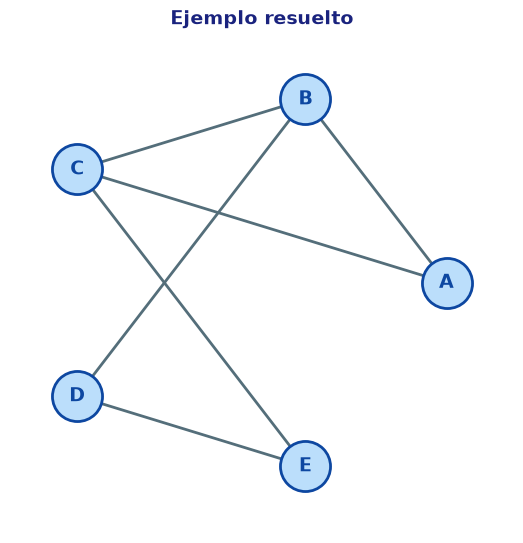

  ✔  n
  ✔  m
  ✔  grados
  ✔  vecinos de B
  ✔  aislados

  5 de 5 correctas


In [11]:
EJ = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E')])
dibujar(EJ, 'Ejemplo resuelto')

ej_n = 5
ej_m = 6
ej_grados = {'A': 2, 'B': 3, 'C': 3, 'D': 2, 'E': 2}
ej_vecinos_B = {'A', 'C', 'D'}
ej_aislados = set()

revisar([
    ('n', ej_n, EJ.number_of_nodes()),
    ('m', ej_m, EJ.number_of_edges()),
    ('grados', ej_grados, dict(EJ.degree())),
    ('vecinos de B', ej_vecinos_B, set(EJ.neighbors('B'))),
    ('aislados', ej_aislados, {v for v in EJ if EJ.degree(v) == 0}),
]);

## 1. Tu código de estudiante

Escribe tu código entre comillas, por ejemplo `CODIGO = '20261234'`, y ejecuta la celda. **No lo cambies después**: si lo cambias, cambian tus grafos.

In [12]:
CODIGO = '80831462'    # <- tu código de estudiante, entre comillas

if CODIGO is None:
    raise ValueError('Escribe tu código de estudiante en CODIGO antes de continuar')
G, D, VND, VD = generar_grafos(str(CODIGO).strip())
print('Grafos generados para el código', CODIGO)
print('Vértice para las preguntas de vecinos:  no dirigido ->', VND, '   dirigido ->', VD)

Grafos generados para el código 80831462
Vértice para las preguntas de vecinos:  no dirigido -> D    dirigido -> S


## 2. Grafo no dirigido

Ejecuta la celda para ver tu grafo.

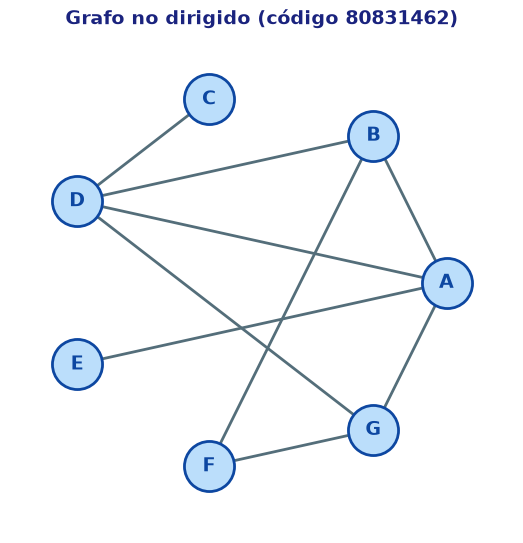

In [13]:
dibujar(G, f'Grafo no dirigido (código {CODIGO})')

**Preguntas.** Responde mirando el dibujo:

1. ¿Cuántos vértices tiene el grafo ($n$)?
2. ¿Cuántas aristas tiene el grafo ($m$)?
3. ¿Cuál es el grado de cada vértice?
4. ¿Cuánto vale la suma de todos los grados? (Compárala con $2m$.)
5. ¿Cuál es el grado **máximo** del grafo? ¿Qué vértices lo tienen?
6. ¿Qué vértices tienen grado **1** (hojas)? ¿Cuáles tienen grado **0** (aislados)?
7. ¿Cuáles son los **vecinos** del vértice indicado en la sección 1 (`VND`)?
8. ¿Cuántas aristas **más** se podrían agregar sin crear aristas paralelas ni lazos? (Recuerda: un grafo simple no dirigido tiene a lo sumo $n(n-1)/2$ aristas.)

In [14]:
nd_n = None                    # 1. número de vértices
nd_m = None                    # 2. número de aristas
nd_grados = {'A': None, 'B': None, 'C': None, 'D': None, 'E': None, 'F': None, 'G': None}   # 3.
nd_suma_grados = None          # 4. suma de los grados
nd_grado_max = None            # 5. grado máximo
nd_vertices_max = None         # 5. conjunto de vértices con el grado máximo, ej. {'A', 'C'}
nd_hojas = None                # 6. conjunto de vértices de grado 1 (set() si no hay)
nd_aislados = None             # 6. conjunto de vértices de grado 0 (set() si no hay)
nd_vecinos = None              # 7. conjunto de vecinos de VND
nd_faltantes = None            # 8. aristas que se podrían agregar

In [15]:
# --- Revisión: grafo no dirigido ---
_g = dict(G.degree())
_max = max(_g.values())
revisar([
    ('1. n', nd_n, G.number_of_nodes()),
    ('2. m', nd_m, G.number_of_edges()),
    ('3. grados', nd_grados, _g),
    ('4. suma de grados', nd_suma_grados, sum(_g.values())),
    ('5. grado máximo', nd_grado_max, _max),
    ('5. vértices con grado máximo', nd_vertices_max, {v for v in _g if _g[v] == _max}),
    ('6. hojas (grado 1)', nd_hojas, {v for v in _g if _g[v] == 1}),
    ('6. aislados (grado 0)', nd_aislados, {v for v in _g if _g[v] == 0}),
    (f'7. vecinos de {VND}', nd_vecinos, set(G.neighbors(VND))),
    ('8. aristas que faltan', nd_faltantes, len(G) * (len(G) - 1) // 2 - G.number_of_edges()),
]);

  …  1. n: sin responder
  …  2. m: sin responder
  …  3. grados: sin responder
  …  4. suma de grados: sin responder
  …  5. grado máximo: sin responder
  …  5. vértices con grado máximo: sin responder
  …  6. hojas (grado 1): sin responder
  …  6. aislados (grado 0): sin responder
  …  7. vecinos de D: sin responder
  …  8. aristas que faltan: sin responder

  0 de 10 correctas


## 3. Grafo dirigido

En el dibujo, cada flecha va del **origen** al **destino**. Si entre dos vértices hay dos flechas curvas, son dos aristas distintas: $u \to v$ y $v \to u$.

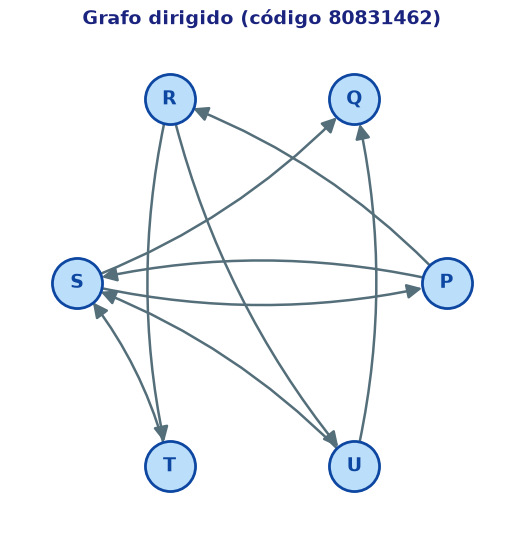

In [16]:
dibujar(D, f'Grafo dirigido (código {CODIGO})')

**Preguntas.** Responde mirando el dibujo:

1. ¿Cuántos vértices ($n$) y cuántas aristas ($m$) tiene el grafo?
2. ¿Cuál es el **grado de salida** ($\text{outdeg}$) de cada vértice?
3. ¿Cuál es el **grado de entrada** ($\text{indeg}$) de cada vértice?
4. ¿Cuánto vale la suma de los grados de salida? ¿Y la de los grados de entrada? (Compáralas con $m$.)
5. ¿Qué vértices son **fuentes** ($\text{indeg} = 0$)? ¿Cuáles son **sumideros** ($\text{outdeg} = 0$)?
6. Para el vértice indicado en la sección 1 (`VD`): ¿cuáles son sus **sucesores** (a dónde llegan sus flechas) y sus **predecesores** (de dónde vienen las flechas que llegan a él)?
7. ¿Qué vértice tiene el **mayor grado total** $\text{indeg}(v) + \text{outdeg}(v)$? Si hay empate, escribe todos en el conjunto.
8. ¿Qué pares de vértices están conectados **en los dos sentidos** ($u \to v$ y $v \to u$)? Escribe cada par como una cadena de dos letras en orden alfabético, por ejemplo `{'PQ', 'RT'}`.

In [17]:
d_n = None                     # 1. número de vértices
d_m = None                     # 1. número de aristas
d_out = {'P': None, 'Q': None, 'R': None, 'S': None, 'T': None, 'U': None}   # 2. outdeg
d_in  = {'P': None, 'Q': None, 'R': None, 'S': None, 'T': None, 'U': None}   # 3. indeg
d_suma_out = None              # 4. suma de los outdeg
d_suma_in = None               # 4. suma de los indeg
d_fuentes = None               # 5. conjunto de fuentes (set() si no hay)
d_sumideros = None             # 5. conjunto de sumideros (set() si no hay)
d_sucesores = None             # 6. conjunto de sucesores de VD
d_predecesores = None          # 6. conjunto de predecesores de VD
d_max_total = None             # 7. conjunto de vértices con mayor indeg + outdeg
d_dos_sentidos = None          # 8. conjunto de pares, ej. {'PQ', 'RT'} (set() si no hay)

In [18]:
# --- Revisión: grafo dirigido ---
_o, _i = dict(D.out_degree()), dict(D.in_degree())
_t = {v: _o[v] + _i[v] for v in D}
revisar([
    ('1. n', d_n, D.number_of_nodes()),
    ('1. m', d_m, D.number_of_edges()),
    ('2. outdeg', d_out, _o),
    ('3. indeg', d_in, _i),
    ('4. suma de outdeg', d_suma_out, sum(_o.values())),
    ('4. suma de indeg', d_suma_in, sum(_i.values())),
    ('5. fuentes', d_fuentes, {v for v in D if _i[v] == 0}),
    ('5. sumideros', d_sumideros, {v for v in D if _o[v] == 0}),
    (f'6. sucesores de {VD}', d_sucesores, set(D.successors(VD))),
    (f'6. predecesores de {VD}', d_predecesores, set(D.predecessors(VD))),
    ('7. mayor grado total', d_max_total, {v for v in D if _t[v] == max(_t.values())}),
    ('8. pares en los dos sentidos', d_dos_sentidos,
     {''.join(sorted((u, v))) for u, v in D.edges() if D.has_edge(v, u)}),
]);

  …  1. n: sin responder
  …  1. m: sin responder
  …  2. outdeg: sin responder
  …  3. indeg: sin responder
  …  4. suma de outdeg: sin responder
  …  4. suma de indeg: sin responder
  …  5. fuentes: sin responder
  …  5. sumideros: sin responder
  …  6. sucesores de S: sin responder
  …  6. predecesores de S: sin responder
  …  7. mayor grado total: sin responder
  …  8. pares en los dos sentidos: sin responder

  0 de 12 correctas


## 4. Para pensar (respuesta escrita)

Responde en esta misma celda, debajo de cada pregunta:

1. En tu grafo no dirigido, ¿por qué la suma de los grados **siempre** es par, sin importar cómo se dibuje?
2. En tu grafo dirigido, ¿por qué la suma de los $\text{outdeg}$ es igual a la suma de los $\text{indeg}$?
3. Si un grafo **no dirigido** se convierte en dirigido reemplazando cada arista $\{u, v\}$ por las dos aristas $u \to v$ y $v \to u$, ¿qué relación hay entre $\deg(v)$ en el grafo original y $\text{indeg}(v)$, $\text{outdeg}(v)$ en el nuevo?
4. En la clase `Graph` de Goodrich, ¿qué llamada da el grado de entrada de `v`? ¿Por qué en un grafo no dirigido `G.degree(v)` y `G.degree(v, False)` dan lo mismo?